Import Libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


Load the dataset

In [12]:
df = pd.read_csv(
    "data/household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (2075259, 9)

First five rows:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


Dataset information and missing values

In [13]:
# 1. Display dataset information
print("Dataset Information:")
df.info()

# 2. Display dataset dimensions
print("\nDataset Shape:")
print(df.shape)

# 3. Display column names
print("\nColumn Names:")
print(df.columns)

# 4. Check missing values
print("\nMissing Values in Each Column:")
print(df.isnull().sum())

# 5. Display basic statistics
print("\nBasic Statistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 142.5 MB

Dataset Shape:
(2075259, 9)

Column Names:
Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')

Missing Values in Each Column:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_inte

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


Handle missing values and duplicates

In [15]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remember which rows originally had missing target values
df_clean["target_missing_originally"] = (
    df_clean["Global_active_power"].isnull()
)

# Select numerical columns
numeric_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# 1. Display missing values before cleaning
print("Missing values before cleaning:")
print(df_clean[numeric_cols].isnull().sum())

# 2. Handle missing values using column means
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].mean()
    )

print("\nMissing values after filling:")
print(df_clean[numeric_cols].isnull().sum())

# 3. Check and remove duplicate records
print(
    "\nDuplicate records before removal:",
    df_clean.duplicated(
        subset=df.columns.tolist()
    ).sum()
)

df_clean = df_clean.drop_duplicates(
    subset=df.columns.tolist()
).copy()

print("Dataset shape after removing duplicates:")
print(df_clean.shape)

# 4. Prepare data for classification
# Do not create labels from originally missing power readings
df_model = df_clean.loc[
    ~df_clean["target_missing_originally"]
].drop(
    columns=["target_missing_originally"]
).copy()

print("\nDataset shape for classification:")
print(df_model.shape)

print(
    "Missing target values:",
    df_model["Global_active_power"].isnull().sum()
)

# Display cleaned data
display(df_model.head())

Missing values before cleaning:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Missing values after filling:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Duplicate records before removal: 0
Dataset shape after removing duplicates:
(2075259, 10)

Dataset shape for classification:
(2049280, 9)
Missing target values: 0


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


# Data visualization

Prepare date and time columns

In [17]:
df_model["Date"] = pd.to_datetime(
    df_model["Date"],
    format="%d/%m/%Y"
)

df_model["Hour"] = pd.to_datetime(
    df_model["Time"],
    format="%H:%M:%S"
).dt.hour

print("Date and time columns prepared!")
display(df_model[["Date", "Time", "Hour"]].head())

Date and time columns prepared!


,Date,Time,Hour
0,2006-12-16,17:24:00,17
1,2006-12-16,17:25:00,17
2,2006-12-16,17:26:00,17
3,2006-12-16,17:27:00,17
4,2006-12-16,17:28:00,17


Line Plot

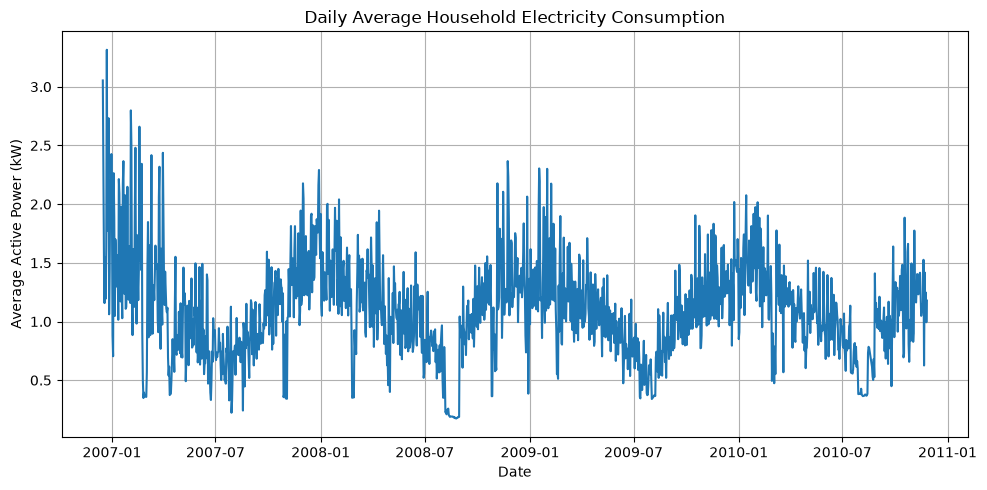

In [18]:
daily_power = df_model.groupby("Date")[
    "Global_active_power"
].mean()

plt.figure(figsize=(10, 5))
plt.plot(daily_power.index, daily_power.values)

plt.title("Daily Average Household Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Average Active Power (kW)")
plt.grid(True)
plt.tight_layout()
plt.show()

Bar Chart

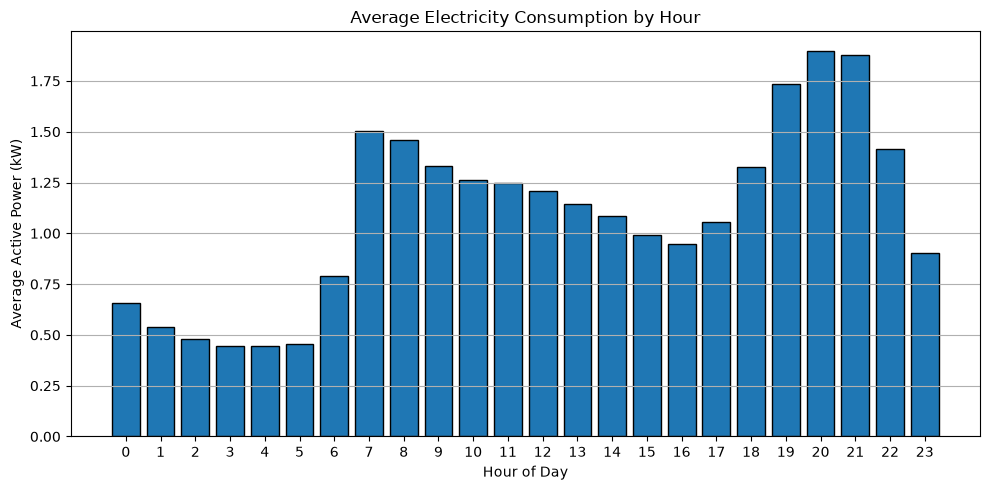

In [21]:
hourly_power = df_model.groupby("Hour")[
    "Global_active_power"
].mean()

plt.figure(figsize=(10, 5))
plt.bar(hourly_power.index, hourly_power.values, edgecolor="black")

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(24))
plt.grid(axis="y")
plt.tight_layout()
plt.show()

Histogram

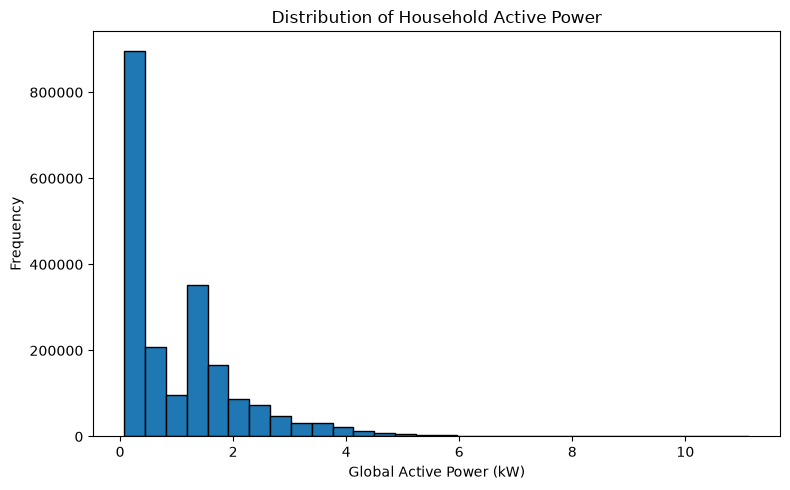

In [22]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_model["Global_active_power"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Household Active Power")
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Scatter Plot

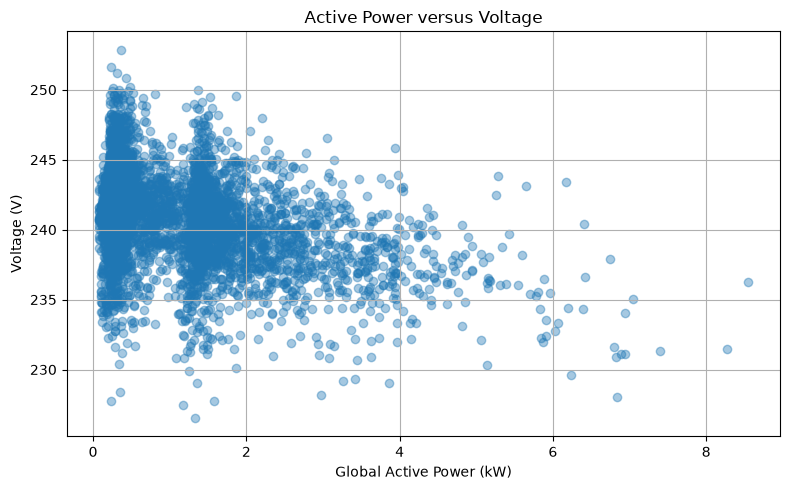

In [29]:
sample_df = df_model.sample(
    n=5000,
    random_state=42
)

plt.figure(figsize=(8, 5))

plt.scatter(
    sample_df["Global_active_power"],
    sample_df["Voltage"],
    alpha=0.4
)

plt.title("Active Power versus Voltage")
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Voltage (V)")
plt.grid(True)
plt.tight_layout()
plt.show()

Create the classification target

In [30]:
# Calculate the median active power
median_power = df_model["Global_active_power"].median()

# Create a new column named Consumption_Class
df_model["Consumption_Class"] = np.where(
    df_model["Global_active_power"] >= median_power,
    "High", 
    "Low"
)

# Display the threshold
print("Median active power:", median_power, "kW")

# Display the number of records in each class
print("\nConsumption class Distribution:")
print(df_model["Consumption_Class"].value_counts())

# Disply the percentage of each class
print("\nClass Distribution in Percentage:")
print(
    (df_model["Consumption_Class"].value_counts(normalize=True) * 100)
    .round(2)
)

# Display sample records
print("\nSample Dataset:")
display(
    df_model[
        ["Date", "Time", "Global_active_power", "Consumption_Class"]
    ].head()
)

Median active power: 0.602 kW

Consumption class Distribution:
Consumption_Class
High    1025299
Low     1023981
Name: count, dtype: int64

Class Distribution in Percentage:
Consumption_Class
High    50.03
Low     49.97
Name: proportion, dtype: float64

Sample Dataset:


,Date,Time,Global_active_power,Consumption_Class
0,2006-12-16,17:24:00,4.216,High
1,2006-12-16,17:25:00,5.360,High
2,2006-12-16,17:26:00,5.374,High
3,2006-12-16,17:27:00,5.388,High
4,2006-12-16,17:28:00,3.666,High


# Prepare the data for machine learning

Select features and target

In [34]:
# Select input features
X = df_model[
    [
        "Global_reactive_power",
        "Voltage",
        "Global_intensity",
        "Sub_metering_1",
        "Sub_metering_2",
        "Sub_metering_3"
    ]
]

# Select target
y = df_model["Consumption_Class"]

print("Input Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Input Features (X):
   Global_reactive_power  Voltage  Global_intensity  Sub_metering_1  \
0                  0.418   234.84              18.4             0.0   
1                  0.436   233.63              23.0             0.0   
2                  0.498   233.29              23.0             0.0   
3                  0.502   233.74              23.0             0.0   
4                  0.528   235.68              15.8             0.0   

   Sub_metering_2  Sub_metering_3  
0             1.0            17.0  
1             1.0            16.0  
2             2.0            17.0  
3             1.0            17.0  
4             1.0            17.0  

Target (y):
0    High
1    High
2    High
3    High
4    High
Name: Consumption_Class, dtype: str

Feature shape: (2049280, 6)
Target shape: (2049280,)


Split the dataset into training and testing data

In [ ]:
# Select 100,000 reproducible random record
sample_df = df_model.sample(
    n=100000,
    random_state=42
)

# Select input features and target from the sample
X = sample_df[
    [
        "Global_reactive_power",
        "Voltage",
        "Global_intensity",
        "Sub_metering_1",
        "Sub_metering_2",
        "Sub_metering_3"
    ]
]

y = sample_df["Consumption_Class"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training Data: (80000, 6)
Testing Data: (20000, 6)

Training target distribution:
Consumption_Class
High    40053
Low     39947
Name: count, dtype: int64

Testing target distribution:
Consumption_Class
High    10013
Low      9987
Name: count, dtype: int64


# Train Decision Tree model

Decision Tree Classification

In [36]:
# Create the model
model_dt = DecisionTreeClassifier(random_state=42)

# Train the model
model_dt.fit(X_train, y_train)

print("Decision Tree Model trained successfully!")

Decision Tree Model trained successfully!


Predict the result

In [39]:
# Predict the class for test data
y_pred_dt = model_dt.predict(X_test)

print("First 20 actual values:")
print(y_test.head(20).tolist())

print("\nFirst 20 predicted values:")
print(y_pred_dt[:20])

First 20 actual values:
['High', 'Low', 'Low', 'Low', 'Low', 'High', 'High', 'Low', 'Low', 'Low', 'High', 'Low', 'High', 'Low', 'High', 'High', 'Low', 'High', 'Low', 'Low']

First 20 predicted values:
['High' 'Low' 'Low' 'Low' 'Low' 'High' 'High' 'Low' 'Low' 'Low' 'High'
 'Low' 'High' 'Low' 'High' 'High' 'Low' 'High' 'Low' 'Low']


Calculate model accuracy

In [40]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Desion Tree Accuracy:", round(accuracy_dt, 4))
print("Accuracy Percentage:", round(accuracy_dt * 100, 2), "%")

Desion Tree Accuracy: 0.9917
Accuracy Percentage: 99.17 %


Display the Confusion Matrix

Confusion Matrix:
[[9917   70]
 [  96 9917]]


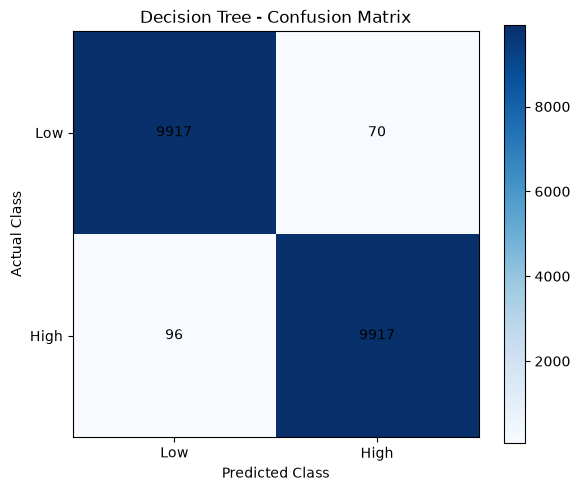

In [45]:
# Confusion Matrix for Decision Tree
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=["Low", "High"]
)

print("Confusion Matrix:")
print(cm_dt)

plt.figure(figsize=(6, 5))
plt.imshow(cm_dt, cmap="Blues")
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["Low", "High"])
plt.yticks([0, 1], ["Low", "High"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm_dt[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

Generate the classification report

In [48]:
# Classification Report
print("Decision Tree Classification report:")

print(
    classification_report(
        y_test,
        y_pred_dt,
        labels=["Low", "High"],
        zero_division=0
    )
)

Decision Tree Classification report:
              precision    recall  f1-score   support

         Low       0.99      0.99      0.99      9987
        High       0.99      0.99      0.99     10013

    accuracy                           0.99     20000
   macro avg       0.99      0.99      0.99     20000
weighted avg       0.99      0.99      0.99     20000



# Train a Logistic Regression model

Scale the features

In [49]:
scaler = StandardScaler()

# Fit the scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data
X_test_scaled = scaler.fit_transform(X_test)

print("Feature Scaling Completed!")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature Scaling Completed!
Training data shape: (80000, 6)
Testing data shape: (20000, 6)


Create and Train the model

In [50]:
# Create Logistic Regression Model
model_lr = LogisticRegression(max_iter=1000)

# Train the model
model_lr.fit(X_train_scaled, y_train)

print("Logistic Regression Model trained successfully!")

Logistic Regression Model trained successfully!


Predict and calculate accuracy

In [51]:
# Make Prediction
y_pred_lr = model_lr.predict(X_test_scaled)

print("First 20 predicted values:")
print(y_pred_lr[:20])

# Calculate accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("\nLogistic Regression Accuracy:", round(accuracy_lr, 4))
print("Accuracy Percentage:", round(accuracy_lr * 100, 2), "%")

First 20 predicted values:
['High' 'Low' 'Low' 'Low' 'Low' 'High' 'High' 'Low' 'Low' 'Low' 'High'
 'Low' 'High' 'Low' 'High' 'High' 'Low' 'High' 'Low' 'Low']

Logistic Regression Accuracy: 0.9925
Accuracy Percentage: 99.25 %


In [60]:
import joblib
from pathlib import Path

# Create a folder for trained models
Path("models").mkdir(exist_ok=True)

# Save the trained Logistic Regression model
joblib.dump(
    model_lr,
    "models/logistic_regression.joblib"
)

# Save the fitted feature scaler
joblib.dump(
    scaler,
    "models/standard_scaler.joblib"
)

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


Display the Classification Report

In [52]:
print("Logistic Regression Classification Report:")

print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=["Low", "High"],
        zero_division=0
    )
)

Logistic Regression Classification Report:
              precision    recall  f1-score   support

         Low       0.99      0.99      0.99      9987
        High       0.99      0.99      0.99     10013

    accuracy                           0.99     20000
   macro avg       0.99      0.99      0.99     20000
weighted avg       0.99      0.99      0.99     20000



Plot the Confusion Matrix

Confusion Matrix:
[[9933   54]
 [  97 9916]]


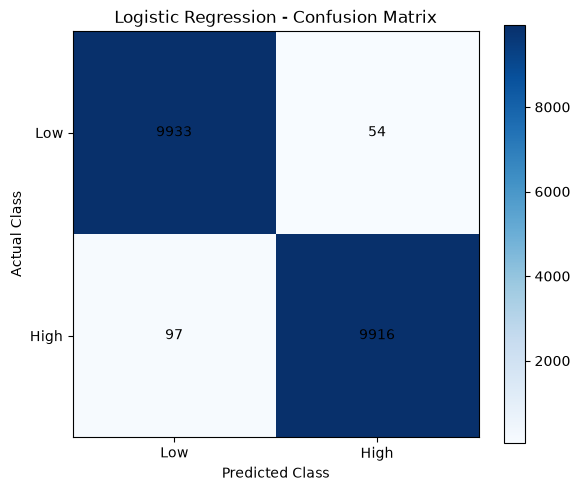

In [53]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=["Low", "High"]
)

print("Confusion Matrix:")
print(cm_lr)

plt.figure(figsize=(6, 5))
plt.imshow(cm_lr, cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["Low", "High"])
plt.yticks([0, 1], ["Low", "High"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm_lr[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

# Compare both classification models

Create a comparison table

In [54]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Logistic Regression"],
    "Accuracy": [accuracy_score(y_test, y_pred_dt), accuracy_score(y_test, y_pred_lr)]
})

comparison["Accuracy (%)"] = (comparison["Accuracy"] * 100).round(2)

print("Model Comparison:")
display(comparison)

Model Comparison:


,Model,Accuracy,Accuracy (%)
0,Decision Tree,0.99170,99.17
1,Logistic Regression,0.99245,99.24


Save your charts for the dashboard

In [61]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create an assets folder
assets_dir = Path("assets")
assets_dir.mkdir(exist_ok=True)

# 1. Daily electricity consumption
daily_power = df_model.groupby("Date")[
    "Global_active_power"
].mean()

plt.figure(figsize=(10, 4))
plt.plot(daily_power.index, daily_power.values)
plt.title("Daily Average Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Active Power (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(assets_dir / "daily_consumption.png", dpi=150)
plt.close()

# 2. Average consumption by hour
hourly_power = df_model.groupby("Hour")[
    "Global_active_power"
].mean()

plt.figure(figsize=(8, 4))
plt.bar(hourly_power.index, hourly_power.values)
plt.title("Average Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Active Power (kW)")
plt.tight_layout()
plt.savefig(assets_dir / "hourly_consumption.png", dpi=150)
plt.close()

# 3. High vs Low class distribution
class_counts = df_model["Consumption_Class"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(class_counts.index, class_counts.values)
plt.title("Consumption Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig(assets_dir / "class_distribution.png", dpi=150)
plt.close()

# 4. Model accuracy comparison
plt.figure(figsize=(7, 4))
plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(assets_dir / "model_comparison.png", dpi=150)
plt.close()

print("All four charts saved successfully!")

for file in assets_dir.iterdir():
    print(file)

All four charts saved successfully!
assets/hourly_consumption.png
assets/class_distribution.png
assets/daily_consumption.png
assets/model_comparison.png


Visualize the comparison

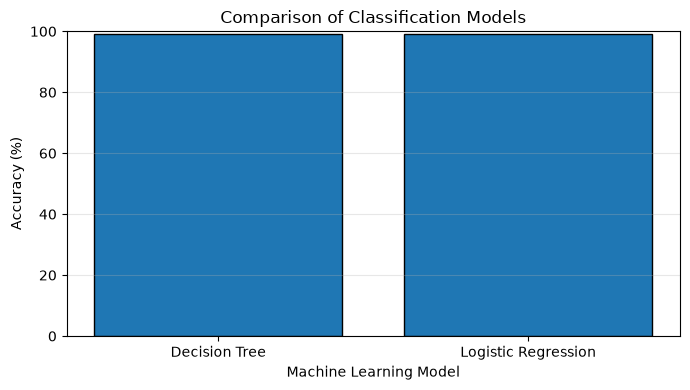

In [56]:
# Compare model accuracy using a bar chart

plt.figure(figsize=(7, 4))

plt.bar(comparison["Model"], comparison["Accuracy (%)"], edgecolor="black")

plt.title("Comparison of Classification Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Build basic Chatbot

Basic Electricity Consumption Chatbot

In [57]:
print("=" * 45)
print(" ELECTRICITY CONSUMPTION CHATBOT ")
print("=" * 45)

print("Bot: Hello! Welcome to the Electricity Project Chatbot.")
print("Bot: Ask me about the project, dataset, or ML models.")
print("Bot: Type 'exit' to end the conversation.")

while True:

    # Get input from the user
    user_input = input("\nYou: ").lower().strip()

    # Check the user's message
    if user_input == "hello" or user_input == "hi":
        print("Bot: Hello! How can I help you?")

    elif user_input == "what is this project":
        print(
            "Bot: This project analyzes household electricity "
            "consumption and classifies it into High and Low classes "
            "using machine learning."
        )

    elif user_input == "dataset":
        print(
            "Bot: We use the UCI Individual Household Electric "
            "Power Consumption dataset. It contains household "
            "electricity measurements recorded over time."
        )

    elif user_input == "high low":
        print(
            "Bot: In our project, consumption is classified as High "
            "or Low using the median Global Active Power as the threshold."
        )

    elif user_input == "models":
        print(
            "Bot: We trained two classification models: "
            "Decision Tree and Logistic Regression."
        )

    elif user_input == "accuracy":
        print(
            "Bot: Both models currently show approximately 99% "
            "precision, recall, and F1-score in the test report. "
            "Check the notebook for the exact accuracy values."
        )

    elif user_input == "help":
        print("Bot: You can ask me about:")
        print("- hello")
        print("- what is this project")
        print("- dataset")
        print("- high low")
        print("- models")
        print("- accuracy")
        print("- exit")

    elif user_input == "exit" or user_input == "quit":
        print("Bot: Goodbye! Thank you for using the chatbot.")
        break

    else:
        print(
            "Bot: Sorry, I don't understand that question. "
            "Type 'help' to see the available commands."
        )

 ELCETRICITY CONSUMPTION CHATBOT 
Bot: Hello! Welcome to the Electricity Project Chatbot.
Bot: Ask me about the project, dataset, or ML models.
Bot: Type 'exit' to end the conversation.
Bot: Hello! How can I help you?
Bot: We use the UCI Individual Household Electric Power Consumption dataset. It contains household electricity measurements recorded over time.
Bot: You can ask me about:
- hello
- what is this project
- dataset
- high low
- models
- accuracy
- exit
Bot: We trained two classification models: Decision Tree and Logistic Regression.
Bot: Both models currently show approximately 99% precision, recall, and F1-score in the test report. Check the notebook for the exact accuracy values.
Bot: In our project, consumption is classified as High or Low using the median Global Active Power as the threshold.
Bot: Goodbye! Thank you for using the chatbot.
